# 01 · Simulate games

**Teklovossen v2 learning series**

| # | Notebook | Question it answers |
|---|---|---|
| **01** | **Simulate games** | How do we get data we can trust out of a game? |
| 02 | Build the dataset | What may a model see, and what must it not see? |
| 03 | Train and evaluate | How good is the model, really? |
| 04 | LLMs with Hugging Face Inference Providers | Can an LLM read card text better than a regex? |
| 05 | Publish | How do we share the model and the data on the Hub? |

This notebook plays many random Teklovossen decks against one fixed opponent and saves the results.
There is no machine learning here yet. The goal is data we can trust.

> Fan-made, educational project. Not affiliated with Legend Story Studios.

## What changed from v1

| Part | Problem in v1 | v2 |
|---|---|---|
| Decks | 9 presets, and 5 of them were the same 20 cards: unknown preset names fell back to the first 20 cards of the database | 800 random decks, all different |
| Game engine | Attack cards were never played from hand, items never entered play, defense was ignored | A small engine where cost, pitch, power, defense, Go again, Boost, items and Evos all matter ([`teklo/engine.py`](../../teklo/engine.py)) |
| Game statistics | Evo counts and resources were set from hand-typed per-deck tables plus random noise | Every number comes from the games |
| Winner label | `Opponent` and `opponent` were both used | `A`, `B` or `draw` |

The v1 notebooks and modules are untouched, so you can compare.

In [1]:
from pathlib import Path
import sys

# Make the teklo package importable, wherever Jupyter was started from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "teklo").is_dir())
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "v2"
DATA.mkdir(parents=True, exist_ok=True)

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import teklo
from teklo.cards import Card
from teklo.engine import play_game
from teklo.plotting import BLUE, SURFACE, use_style

use_style()
pd.set_option("display.max_colwidth", 60)

## 1. Load the cards

Two sources are combined: the official card database (`notebooks/card.csv`) and the fan-made cards (`custom_cards.csv`).
The simulator keeps the cards a Teklovossen deck plays from hand: **attacks**, non-attack **actions**, **instants**, **items** and **Evo** equipment.
Mechanologist, fan-made and Generic cards are allowed; other classes are not.

In [2]:
cards = teklo.load_cards(ROOT / "notebooks" / "card.csv", ROOT / "custom_cards.csv")
pool = teklo.teklo_pool(cards)       # what a Teklovossen deck may play
generic = teklo.generic_pool(cards)  # what the reference opponent plays
table = teklo.cards_frame(pool)

print(f"{len(pool)} cards a Teklovossen deck can use, {table.custom.sum()} of them fan-made")
table.pivot_table(index="theme", columns="kind", values="id", aggfunc="count", fill_value=0)

698 cards a Teklovossen deck can use, 34 of them fan-made


kind,action,attack,evo,instant,item
theme,,,,,
AI,0,0,0,0,4
Bio,1,0,8,0,6
Generic,99,223,0,37,28
Mechanologist,34,164,33,1,49
Nano,1,0,5,1,2
Quantum,0,0,2,0,0


### Rules text → numbers

A simulator can't read English. `teklo.parse_effects` is a deliberately small keyword parser: it finds
*Go again*, *Boost*, `+N{p}` power bonuses, "draw a card", "gain N{r}" resources, "deal N damage" and "gain N{h}" life.
Everything else in the text is ignored.

In [3]:
example = "The next attack action card you play this turn gains +2{p}. Draw a card."
teklo.parse_effects(example, keywords=("Go again",), kind="action")

Effects(go_again=True, boost=False, power_bonus=2, draw=1, energy=0, damage=0, life=0)

Now the fan-made cards. The `fx_` columns are what the parser understood:

In [4]:
fx_cols = ["fx_go_again", "fx_boost", "fx_power_bonus", "fx_draw", "fx_energy", "fx_damage", "fx_life"]
table.loc[table.custom, ["id", "kind", "cost", "pitch", "power", "defense", *fx_cols]].reset_index(drop=True)

,id,kind,cost,pitch,power,defense,fx_go_again,fx_boost,fx_power_bonus,fx_draw,fx_energy,fx_damage,fx_life
0,AI - Overclock Core (1),item,1,1,0,0,False,False,2,0,0,0,0
1,AI - Predator Logic (1),item,2,1,0,0,False,False,0,0,0,0,0
2,AI - Singularity Cannon (1),item,2,1,6,0,False,False,0,0,0,0,0
3,AI - Nemesis Driver (1),item,1,1,0,0,False,False,0,0,0,0,0
4,Evo - Nanite Core Reactor (1),evo,3,1,0,3,False,False,0,0,0,0,0
5,Evo - NeuroWeave Visor (1),evo,2,1,0,3,False,False,0,0,0,0,0
6,Evo - Phage Arms (1),evo,2,1,0,3,False,False,0,0,0,0,0
7,Evo - Swarm-Forged Tower (1),evo,2,1,0,3,False,False,0,0,0,0,0
8,Item - Nanite Forge (1),item,2,1,0,0,False,False,0,0,0,0,0
9,Item - Cloakfield Generator (1),item,1,1,0,0,False,False,0,0,0,0,0


Only one fan-made card has anything in its `fx_` columns: **AI - Overclock Core** (+2 power, every turn, since it is an item).
That is not the parser's fault. `custom_cards.csv` stores only a type line for most fan-made cards (for example *Mechanologist Equipment - Chest - Evo Nano*); their real rules text lives in `teklostudy.md`, which the parser never reads.
So for now the simulator judges these cards on their stats alone: cost, pitch, power and defense.
Notebook 04 asks an LLM to read the design document and fill these columns in.

## 2. The reference opponent

Every deck is measured against the **same** opponent, so their win rates can be compared.
It is a fixed Generic deck: efficient attacks (power at least cost + 3) plus a few non-attack actions.

In [5]:
opponent = teklo.reference_opponent(generic)
by_id = {c.id: c for c in opponent}
pd.DataFrame([
    {"card": cid, "copies": n, "kind": by_id[cid].kind, "cost": by_id[cid].cost,
     "power": by_id[cid].power, "pitch": by_id[cid].pitch}
    for cid, n in teklo.deck_counts(opponent).items()
])

,card,copies,kind,cost,power,pitch
0,Flock of the Feather Walkers (2),3,attack,1,4,2
1,Standing Order (1),3,attack,0,4,1
2,Wage Gold (2),3,attack,3,6,2
3,Wounded Bull (2),3,attack,3,6,2
4,Fyendal's Fighting Spirit (2),3,attack,3,6,2
5,Wounding Blow (1),3,attack,0,4,1
6,Stony Woottonhog (2),3,attack,2,5,2
7,Raging Onslaught (1),3,attack,3,7,1
8,Seduce Secrets (2),2,instant,0,0,2
9,Sun Kiss (2),2,action,0,0,2


## 3. Watch one game

The rules, in short:

* 20 life each, a weapon (3 power, costs 1, once per turn) and four base equipment pieces (1 defense each).
* One action point per turn. Pay costs by pitching cards (red 1, yellow 2, blue 3) or with stored Teklo Energy.
* Go again, items, Evos and instants give the action point back. Boost banishes your top card; if it isn't Generic, the attack gets Go again.
* The defender blocks with equipment first (it wears down), then with up to two cards from hand.
* Draw back up to 4 cards at the end of your turn. After 40 turns, more life wins.

Reading one game play by play is the fastest way to spot a broken rule:

In [6]:
log = []
result = play_game(opponent, opponent, seed=42, log=log)
print("\n".join(log[:24]))
print("...")
print(log[-1])

--- turn 1: A (life 20) vs B (life 20)
A plays Sun Kiss (2) (bonus now +0)
A attacks with Raging Onslaught (1)
  7 power, 7 blocked, 0 damage -> B at 20
--- turn 2: B (life 20) vs A (life 22)
B attacks with Fyendal's Fighting Spirit (2)
  6 power, 4 blocked, 2 damage -> A at 20
--- turn 3: A (life 20) vs B (life 21)
A attacks with Wounded Bull (2)
  6 power, 6 blocked, 0 damage -> B at 21
--- turn 4: B (life 21) vs A (life 20)
B attacks with Stony Woottonhog (2)
  5 power, 3 blocked, 2 damage -> A at 18
--- turn 5: A (life 18) vs B (life 21)
A attacks with Wounded Bull (2)
  6 power, 4 blocked, 2 damage -> B at 19
--- turn 6: B (life 19) vs A (life 18)
B attacks with the weapon
  3 power, 3 blocked, 0 damage -> A at 18
--- turn 7: A (life 18) vs B (life 19)
A plays Seduce Secrets (2) (bonus now +0)
A plays Sun Kiss (2) (bonus now +0)
A plays Visit the Blacksmith (3) (bonus now +1)
A attacks with Wounding Blow (1)
...
=== winner: A after 25 turns (A 13, B -3)


## 4. Sanity checks

A simulator is a hypothesis about the game. Before using its numbers, test it on cases where you already know the answer.

In [7]:
filler = Card(id="Blue filler (3)", name="Blue filler", kind="action", cost=0, pitch=3, power=0,
              defense=2, slot=None, theme="Generic", custom=False)

mirror = teklo.evaluate_deck(opponent, opponent, n_games=1000, seed=1)
first = [play_game(opponent, opponent, seed=s, a_first=True).winner for s in range(1000)]
no_attacks = teklo.evaluate_deck([filler] * 30, opponent, n_games=200, seed=2)

pd.DataFrame([
    {"check": "Deck against itself", "expected": "about 50%", "result": f"{mirror['win_rate']:.0%}"},
    {"check": "Player who goes first", "expected": "an edge, not a certainty", "result": f"{first.count('A') / len(first):.0%}"},
    {"check": "30 blue cards, no attacks", "expected": "close to 0%", "result": f"{no_attacks['win_rate']:.0%}"},
])

,check,expected,result
0,Deck against itself,about 50%,53%
1,Player who goes first,"an edge, not a certainty",63%
2,"30 blue cards, no attacks",close to 0%,0%


All three behave as expected. The mirror match lands at 53% rather than exactly 50%: over 1,000 games, luck alone moves the result by up to about 3 points. Going first is a real edge in this simulator (63%). That is why `evaluate_deck` alternates who goes first: the advantage cancels out.

## 5. Random decks

v1 had 9 decks. A model that learns from 9 rows can only memorise them.
Here every deck is random but deck-like: 10 to 15 different cards, 1 to 3 copies each, 30 cards in total.
Each deck also draws its own preferences (more attacks or more items, more or fewer fan-made cards), so the decks really differ.

In [8]:
example_deck = teklo.random_deck(pool, np.random.default_rng(0))
pd.Series(teklo.deck_counts(example_deck), name="copies").rename_axis("card").reset_index()

,card,copies
0,Evo Charging Rods (2),3
1,Fuel Injector (3),2
2,Evo - Quantum Processor (1),1
3,Liquid-Cooled Mayhem (3),3
4,Crankshaft (3),3
5,AI - Nemesis Driver (1),2
6,Potion of Ironhide (3),1
7,Evo Bio-Root Tower (1),2
8,AI - Singularity Cannon (1),3
9,Polarity Reversal Script (1),3


## 6. Simulate

800 decks × 50 games = 40,000 games, alternating who goes first. This takes under a minute.

In [9]:
N_DECKS, GAMES_PER_DECK = 800, 50
rng = np.random.default_rng(2025)

results, deck_cards = [], []
start = time.perf_counter()
for deck_id in range(N_DECKS):
    deck = teklo.random_deck(pool, rng)
    outcome = teklo.evaluate_deck(deck, opponent, n_games=GAMES_PER_DECK, seed=deck_id)
    results.append({"deck_id": deck_id, **outcome})
    deck_cards += [{"deck_id": deck_id, "card_id": cid, "copies": n}
                   for cid, n in teklo.deck_counts(deck).items()]

results = pd.DataFrame(results)
deck_cards = pd.DataFrame(deck_cards)
print(f"{N_DECKS * GAMES_PER_DECK:,} games in {time.perf_counter() - start:.0f} s")
results.drop(columns="deck_id").describe().round(3)

40,000 games in 22 s


,games,wins,draws,win_rate,avg_turns,avg_life_diff
count,800.0,800.000,800.000,800.000,800.000,800.000
mean,50.0,17.138,0.008,0.343,23.720,-4.645
std,0.0,16.845,0.100,0.337,4.891,13.320
min,50.0,0.000,0.000,0.000,10.060,-20.640
25%,50.0,1.000,0.000,0.020,20.740,-13.665
50%,50.0,12.000,0.000,0.240,23.770,-7.200
75%,50.0,31.000,0.000,0.620,26.765,1.240
max,50.0,50.000,2.000,1.000,39.500,74.100


## 7. Look at the target

`win_rate` is what the model will predict. Two questions before going further:
is there spread between decks (if every deck won 50%, there would be nothing to learn), and how much of it is luck?

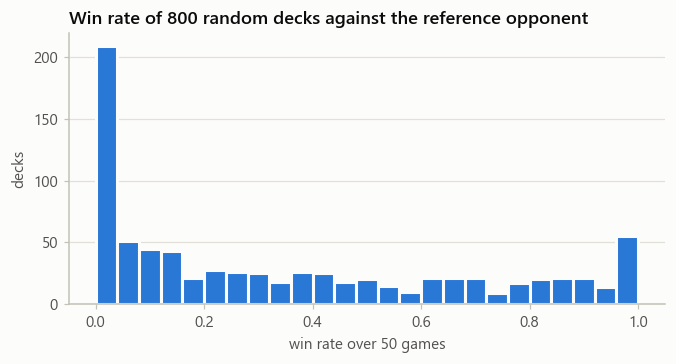

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(results.win_rate, bins=np.linspace(0, 1, 26), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.set_title(f"Win rate of {N_DECKS} random decks against the reference opponent")
ax.set_xlabel(f"win rate over {GAMES_PER_DECK} games")
ax.set_ylabel("decks")
ax.grid(axis="x", visible=False)
plt.show()

In [11]:
p = results.win_rate
luck = np.sqrt((p * (1 - p)).mean() / GAMES_PER_DECK)
print(f"Spread between decks (std):            {p.std():.3f}")
print(f"Luck in a {GAMES_PER_DECK}-game win rate (std):      {luck:.3f}")
print(f"Share of the spread that is deck strength: about {1 - luck**2 / p.var():.0%}")

Spread between decks (std):            0.337
Luck in a 50-game win rate (std):      0.047
Share of the spread that is deck strength: about 98%


The spread between decks is much bigger than the luck in 50 games, so most of what we will predict is real deck strength.
Keep that last number in mind: notebook 03 uses it as the best score any model could reach.

## 8. Save

In [12]:
results.to_csv(DATA / "results.csv", index=False)
deck_cards.to_csv(DATA / "deck_cards.csv", index=False)
table.to_csv(DATA / "cards.csv", index=False)
(pd.Series(teklo.deck_counts(opponent), name="copies").rename_axis("card_id").reset_index()
   .to_csv(DATA / "opponent.csv", index=False))

for f in sorted(DATA.glob("*.csv")):
    print(f"{f.relative_to(ROOT).as_posix():28} {f.stat().st_size / 1024:6.0f} KB")

data/v2/cards.csv               149 KB
data/v2/deck_cards.csv          259 KB
data/v2/opponent.csv              0 KB
data/v2/results.csv              23 KB
data/v2/teklo_decks.csv         104 KB


Next: **02 · Build the dataset**.